In [21]:
import pandas as pd

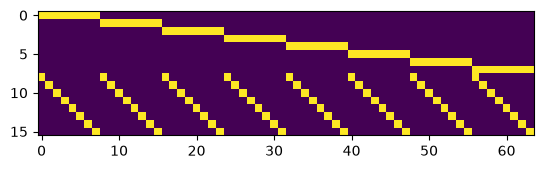

[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
[0.  1.7 3.3 2.3 2.  2.4 1.4 0. ] [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]


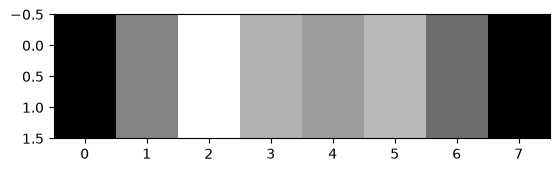

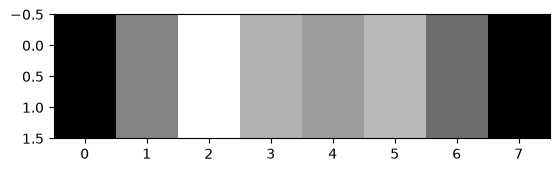

Dimensiones de A2:  (16, 64)
Dimensiones de A4:  (46, 64)
Dimensiones de A7:  (119, 64) 

Rango de A2:  15
Rango de A4:  39
Rango de A7:  64 

dim(Nul A2):  49
dim(Nul A4):  25
dim(Nul A7):  0 



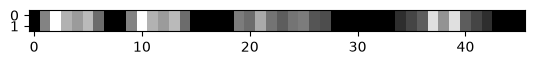

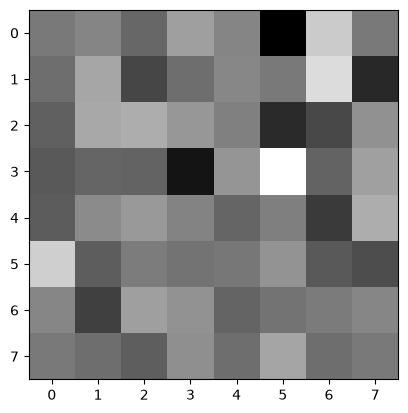

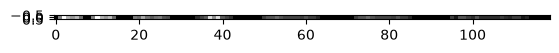

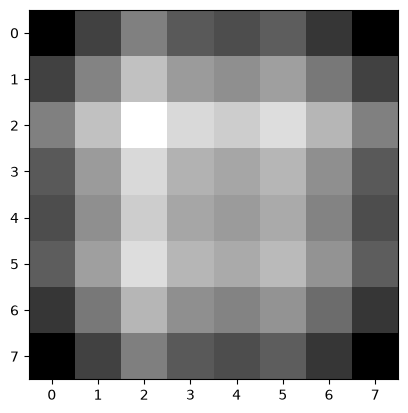

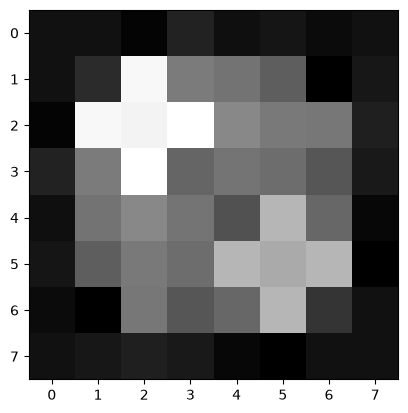

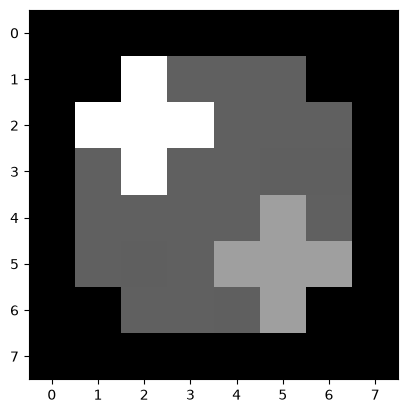

[-0.  0. -0. -0.  0.  0. -0.  0. -0.  0. -0. -0.  0.  0.  0.  0.  0.  0.
 -0. -0. -0. -0. -0.  0.  0. -0. -0.  0.  0.  0. -0. -0. -0. -0. -0.  0.
 -0.  0. -0.  0. -0.  0. -0. -0. -0. -0.  0. -0. -0.  0. -0.  0. -0.  0.
 -0.  0. -0.  0. -0. -0. -0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0.  0.
 -0. -0.  0. -0. -0. -0.  0.  0.  0.  0.  0.  0. -0.  0.  0.  0. -0.  0.
 -0. -0.  0.  0. -0.  0.  0.  0. -0. -0. -0. -0. -0.  0. -0.  0. -0.  0.
  0. -0. -0. -0. -0.  0.  0. -0. -0. -0. -0.]
[-2.90166429e-03  1.58089464e-02 -5.34564624e-03 -7.01874121e-03
  2.80719698e-02  5.62687767e-03 -9.97742926e-03  4.19442478e-03
 -5.61270598e-03  2.42282410e-02 -1.55443817e-02 -6.90301800e-03
  3.10848712e-03  2.24705095e-02  1.07652806e-02  1.35317345e-02
  8.71122731e-03  1.05526290e-02 -5.41228664e-04 -5.97831605e-03
 -3.91112531e-04 -1.57789005e-03 -1.37833934e-02  7.69946695e-03
  1.30277862e-02 -3.20209579e-03 -9.46929597e-03  1.35708451e-02
  1.98286393e-02  1.35875940e-02 -2.67952319e-02 -7.85874487e

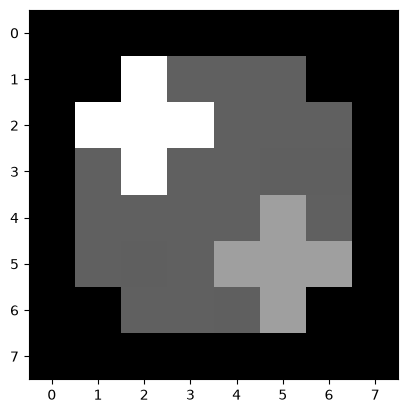

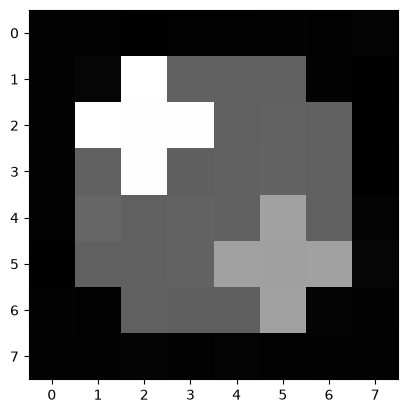

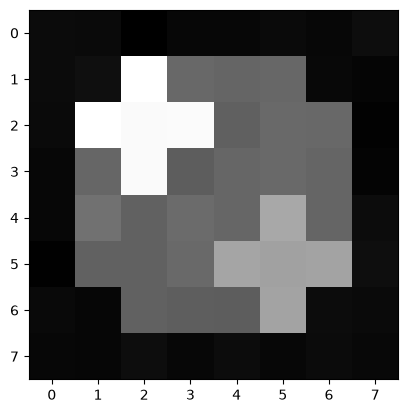

4.3470676454194815e-14


In [22]:
%run ejercicio_7.ipynb

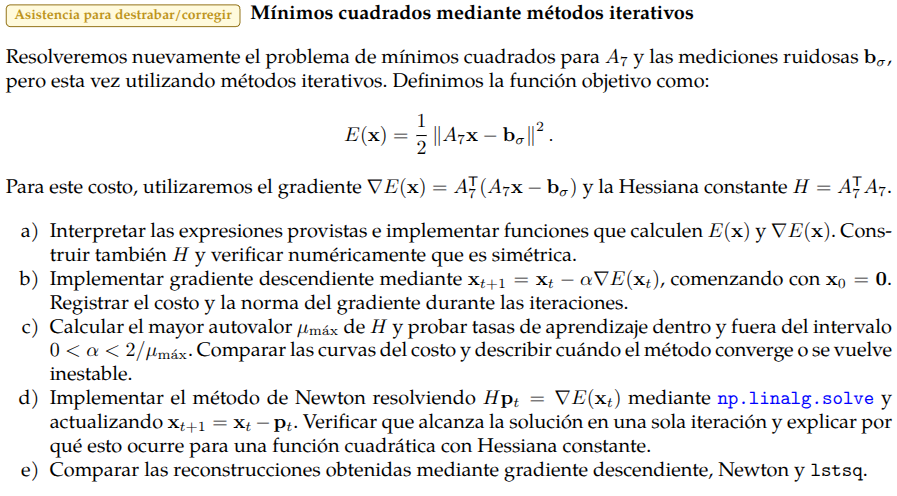

1. Hacemos inciso 1 xd

In [ ]:
def E(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return 0.5*(np.linalg.norm(b_real - b_sigma)**2)

def E_gradient(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return A7.transpose() @ (b_real - b_sigma)

def is_simetrical(A:np.ndarray)->bool:
    if np.array_equal(A.transpose(), A): return True
    return False

A7 = np.array(A7)
hessiano = A7.transpose() @ A7
is_simetrical(hessiano)

True

Nosotros comprendemos lo siguiente:

- $E(x)\rightarrow$ es la función objetivo.
- $\nabla E(x)\rightarrow$ es la función objetivo.
- $H_f(x)\rightarrow$ es el hessiano.

Estos lo usaremos para hacer el descenso del gradiente respecto a la distancia entre nuestra solución parcial y la mejor aproximación factible, es decir, aquella para la cual $E(\hat{x}) = \frac{1}{2}||A_7\hat{x} - b_\sigma||² = \frac{1}{2}||b_7 - b_\sigma||² = \frac{1}{2}||r_\sigma||²$.


2. Implementamos el descenso del gradiente

In [ ]:
# Máxima cantidad de iteraciones (previene loops infinitos)
MAX_ITER = 1000

# Criterio de convergencia (identifica un "plateau")
TOLERANCIA = 0.0001

In [ ]:
# Función de búsqueda del mínimo de f(x)
def gradiente_descendente(x_0, bs, alpha = 0.01, TOLERANCIA = 0.0001):
    # Valor inicial de x
    x_t   = x_0

    # Definimos un historial para el valor del costo y la norma del gradiente
    cost_log = list()
    grad_norm_log = list()

    # Factor de escala de la derivada de f (hiperparámetro)

    # Mientras no hayamos llegado al maximo de iteraciones
    iter  = 0

    while iter <= MAX_ITER:
        print("Iteración: ", iter, "- Mínimo alcanzado hasta el momento: ", E(x_t,bs))
        # Computamos siguiente x a partir de la derivada de la función
        x_tsig = x_t - alpha * E_gradient(x_t,bs)

        # Actualizamos los historiales
        cost_log.append(E(x_t,bs))
        grad_norm_log.append(np.linalg.norm(E_gradient(x_t,bs)))

        # Chequeamos si ya alcanzamos la convergencia
        if abs(E(x_tsig,bs) - E(x_t,bs)) < TOLERANCIA:
          break

        # Preparamos la siguiente iteración
        x_t = x_tsig
        iter = iter + 1

    return x_tsig

In [ ]:
x_tsig = gradiente_descendente(np.zeros((64)), med_ruido[1])
x_tsig

Iteración:  0 - Mínimo alcanzado hasta el momento:  0.22847170749059156


array([ 3.22468128e-04,  4.35084510e-03, -6.02827821e-03,  1.81133932e-03,
       -1.97186741e-03,  2.80982824e-03, -2.96394592e-03,  3.93778137e-03,
        3.20162979e-03,  5.71874893e-03,  7.87038641e-04,  2.23835796e-03,
        8.38713515e-04,  4.56090509e-03,  2.84716738e-03,  2.26345217e-03,
       -1.42296254e-03,  3.92271968e-03, -3.33207197e-03, -7.27290791e-04,
       -5.05287451e-03,  4.36935908e-03,  4.89881050e-04, -1.94007786e-04,
       -1.85704314e-03, -3.57782306e-04, -3.64344201e-03, -4.93270752e-03,
        3.04756191e-03,  4.05860403e-03,  8.69916606e-04, -3.35373915e-03,
       -2.09047526e-03,  9.06658810e-03, -4.08696390e-03,  6.07848241e-03,
        2.63838255e-03,  9.30295655e-03,  3.43094680e-03,  6.57319754e-03,
       -2.38689737e-03, -1.89531589e-03, -1.26599999e-03,  3.67245350e-03,
        3.44444828e-03, -3.07708521e-06,  3.05319227e-03,  3.61234194e-03,
       -2.84461645e-03,  1.01463878e-03, -5.24227394e-03, -3.12494171e-03,
       -3.99683925e-03,  